# Analisis Dataset Spotify Songs

Notebook ini berisi alur kerja lengkap:
1. Loading Data
2. Cleaning Data
3. EDA & EXDA (Exploratory & Extended Data Analysis)
4. Processing Data
5. Splitting Data
6. Modelling Data

## 1. Loading Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset
df = pd.read_csv('spotify_songs.csv')
print('Dimensi dataset awal:', df.shape)
df.head()

Dimensi dataset awal: (32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


## 2. Cleaning Data

In [2]:
# Menghapus missing values pada kolom-kolom kritis
df_clean = df.dropna(subset=['track_name', 'track_artist', 'track_album_name']).copy()

# Menghapus duplikat berdasarkan track_id
df_clean = df_clean.drop_duplicates(subset=['track_id'])

print('Dimensi dataset setelah pembersihan:', df_clean.shape)

Dimensi dataset setelah pembersihan: (28352, 23)


In [7]:
# 1. Menampilkan jumlah missing values di setiap kolom sebelum dibersihkan
print('Jumlah Missing Values per Kolom:')
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Menghapus missing values pada kolom-kolom kritis
df_clean = df.dropna(
    subset=['track_name', 'track_artist', 'track_album_name']
).copy()

# 3. Menghapus duplikat berdasarkan track_id
df_clean = df_clean.drop_duplicates(subset=['track_id'])

print('\nDimensi dataset setelah pembersihan:', df_clean.shape)

Jumlah Missing Values per Kolom:
track_name          5
track_artist        5
track_album_name    5
dtype: int64

Dimensi dataset setelah pembersihan: (28352, 23)


## 3. EDA & EXDA (Exploratory & Extended Data Analysis)

,track_popularity,danceability,energy,loudness,speechiness,acousticness,valence,tempo
count,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000,28352.000000
mean,39.335320,0.653375,0.698373,-6.817777,0.107939,0.177192,0.510386,120.958219
std,23.699443,0.145791,0.183508,3.036433,0.102547,0.222814,0.234344,26.954502
min,0.000000,0.000000,0.000175,-46.448000,0.000000,0.000000,0.000000,0.000000
25%,21.000000,0.561000,0.579000,-8.310250,0.041000,0.014300,0.329000,99.972000
50%,42.000000,0.670000,0.722000,-6.261000,0.062600,0.079700,0.512000,121.993500
75%,58.000000,0.760000,0.843000,-4.708750,0.133000,0.260000,0.695000,133.999000
max,100.000000,0.983000,1.000000,1.275000,0.918000,0.994000,0.991000,239.440000


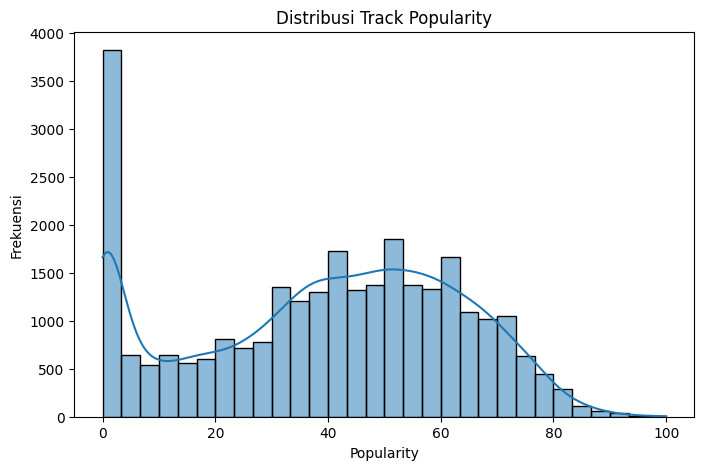

In [3]:
# Ringkasan statistik variabel numerik
display(df_clean[['track_popularity', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'valence', 'tempo']].describe())

# Distribusi Popularitas Lagu
plt.figure(figsize=(8, 5))
sns.histplot(df_clean['track_popularity'], bins=30, kde=True)
plt.title('Distribusi Track Popularity')
plt.xlabel('Popularity')
plt.ylabel('Frekuensi')
plt.show()

## 4. Processing Data

In [4]:
# Pemilihan Fitur & Variabel Target
features = ['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'playlist_genre']

df_model = df_clean[features + ['track_popularity']].copy()

# One-Hot Encoding pada fitur kategorikal (playlist_genre)
df_model = pd.get_dummies(df_model, columns=['playlist_genre'], drop_first=True)

X = df_model.drop(columns=['track_popularity'])
y = df_model['track_popularity']

## 5. Splitting Data

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Membagi data menjadi Train Set (80%) dan Test Set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Penskalaan fitur (Feature Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Bentuk X_train:', X_train.shape)
print('Bentuk X_test:', X_test.shape)

Bentuk X_train: (22681, 17)
Bentuk X_test: (5671, 17)


## 6. Modelling Data

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Inisialisasi dan Pelatihan Model
model = RandomForestRegressor(n_estimators=50, random_state=42, max_depth=10)
model.fit(X_train_scaled, y_train)

# Prediksi
y_pred = model.predict(X_test_scaled)

# Evaluasi Model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE): {mse:.4f}')
print(f'R2 Score: {r2:.4f}')

Mean Squared Error (MSE): 505.1609
R2 Score: 0.1081
